In [30]:
 
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from flask import Flask, request, render_template, render_template_string
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras

In [31]:
app = Flask(__name__)

In [32]:


Real_File = os.listdir(r'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Real')
print(Real_File[0:5])
print(Real_File[-5:])


['Real (1).jpg', 'Real (10).jpg', 'Real (100).jpg', 'Real (1000).jpg', 'Real (1001).jpg']
['Real (995).jpg', 'Real (996).jpg', 'Real (997).jpg', 'Real (998).jpg', 'Real (999).jpg']


In [33]:
Fake_File = os.listdir(r'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Fake')
print(Fake_File[0:5])
print(Fake_File[-5:])

['Fake (1).jpg', 'Fake (10).jpg', 'Fake (100).jpg', 'Fake (1000).jpg', 'Fake (1001).jpg']
['Fake (995).jpg', 'Fake (996).jpg', 'Fake (997).jpg', 'Fake (998).jpg', 'Fake (999).jpg']


In [34]:
print('Number of real images:', len(Real_File))
print('Number of fake images:', len(Fake_File))

Number of real images: 2000
Number of fake images: 2000


In [35]:
real_path='D:\deepfake_detector\Data\Real'
fake_path='D:\deepfake_detector\Data\Fake'

def load_data(real_path, fake_path):
    real_files = os.listdir(real_path)
    fake_files = os.listdir(fake_path)

    data = []
    labels = []

    for img_file in real_files:
        image = Image.open(os.path.join(real_path, img_file)).resize((128, 128)).convert('RGB')
        data.append(np.array(image))
        labels.append(1)  # Real images

    for img_file in fake_files:
        image = Image.open(os.path.join(fake_path, img_file)).resize((128, 128)).convert('RGB')
        data.append(np.array(image))
        labels.append(0)  # Fake images
  
    return np.array(data), np.array(labels)

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
C:\Users\saite\AppData\Local\Temp\ipykernel_26820\1502576965.py:1: SyntaxWarning: invalid escape sequence '\d'
  real_path='D:\deepfake_detector\Data\Real'
C:\Users\saite\AppData\Local\Temp\ipykernel_26820\1502576965.py:2: SyntaxWarning: invalid escape sequence '\d'
  fake_path='D:\deepfake_detector\Data\Fake'


**Displaying the Images**

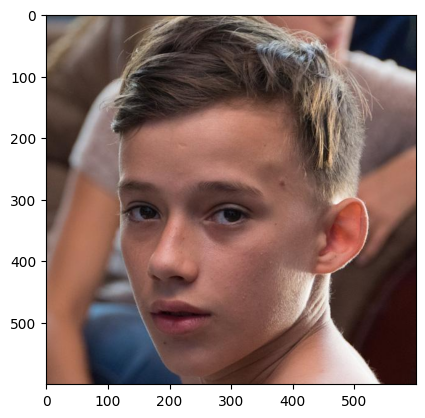

In [ ]:

img = mpimg.imread(r'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Real\Real (1).jpg')
imgplot = plt.imshow(img)
plt.show()

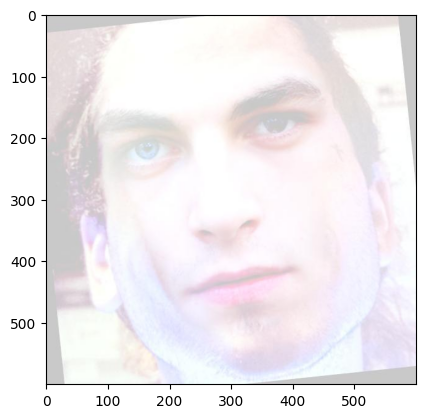

In [37]:
# displaying fake image
img = mpimg.imread(r'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Fake\Fake (1).jpg')
imgplot = plt.imshow(img)
plt.show()

**Load the dataset**

In [38]:

import os
print(os.getcwd())

b:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application


In [39]:
X, Y = load_data('B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Real', 'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Fake')
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

<>:1: SyntaxWarning: invalid escape sequence '\p'
<>:1: SyntaxWarning: invalid escape sequence '\p'
<>:1: SyntaxWarning: invalid escape sequence '\p'
<>:1: SyntaxWarning: invalid escape sequence '\p'
C:\Users\saite\AppData\Local\Temp\ipykernel_26820\3258824336.py:1: SyntaxWarning: invalid escape sequence '\p'
  X, Y = load_data('B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Real', 'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Fake')
C:\Users\saite\AppData\Local\Temp\ipykernel_26820\3258824336.py:1: SyntaxWarning: invalid escape sequence '\p'
  X, Y = load_data('B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Real', 'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\Data\Fake')


In [40]:

def create_model():
    model = keras.Sequential([
        keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(128, 128, 3)),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = create_model()

history=model.fit(X_train / 255.0, Y_train, validation_data=(X_test / 255.0, Y_test), epochs=10, batch_size=32)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 49s 340ms/step - accuracy: 0.5394 - loss: 0.8941 - val_accuracy: 0.6438 - val_loss: 0.6503
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 276ms/step - accuracy: 0.6471 - loss: 0.6178 - val_accuracy: 0.7312 - val_loss: 0.5323
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 281ms/step - accuracy: 0.7575 - loss: 0.4891 - val_accuracy: 0.8225 - val_loss: 0.3942
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 281ms/step - accuracy: 0.8598 - loss: 0.3249 - val_accuracy: 0.8888 - val_loss: 0.2585
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 30s 303ms/step - accuracy: 0.9246 - loss: 0.1950 - val_accuracy: 0.8925 - val_loss: 0.2666
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 31s 305ms/step - accuracy: 0.9239 - loss: 0.1571 - val_accuracy: 0.9262 - val_loss: 0.1916
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 300ms/step - accuracy: 0.9405 - loss: 0.1449 - val_accuracy: 0.9300 - val_loss: 0.2011
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 29s 289ms/step - accuracy: 0.9499 - loss: 0

**Model Evaluation**

In [41]:
loss, accuracy = model.evaluate(X_test / 255.0, Y_test)
print('Test Accuracy =', accuracy)

25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.9335 - loss: 0.1527
Test Accuracy = 0.9300000071525574


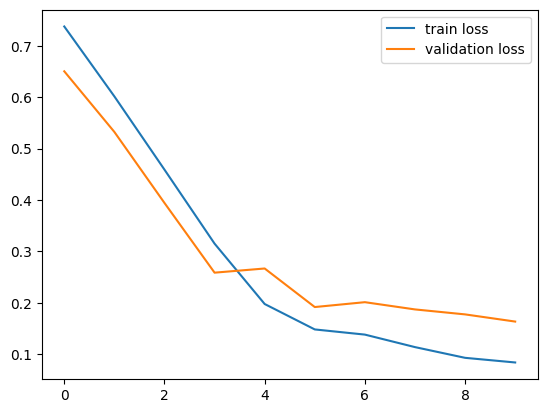

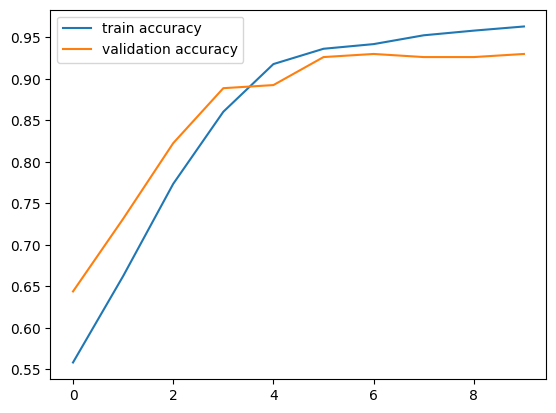

In [42]:
h = history


plt.plot(h.history['loss'], label='train loss')
plt.plot(h.history['val_loss'], label='validation loss')
plt.legend()
plt.show()

plt.plot(h.history['accuracy'], label='train accuracy')
plt.plot(h.history['val_accuracy'], label='validation accuracy')
plt.legend()
plt.show()



**Save the model**

In [43]:
model.save(r'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\model\deepfake_detector.h5', include_optimizer=False)

**Load the trained model**

In [44]:
model.compile()
model = keras.models.load_model(r'B:\projects\deepfake detection\Deepfake-Image-Detection-Using-Deep-Learning-A-CNN-Based-Flask-Web-Application\model\deepfake_detector.h5')

**Predict function**

In [46]:
def predict_image(image_path):
    
    image = cv2.imread(image_path)
    

    image_resized = cv2.resize(image, (128, 128))
    
    image_scaled = image_resized.astype('float32') / 255.0
    
    image_reshaped = np.reshape(image_scaled, [1, 128, 128, 3])
    
    prediction = model.predict(image_reshaped)
    
    print(prediction)
    
    
    input_pred_label = np.argmax(prediction)

    print(input_pred_label)
    
    return "Real" if prediction[0][0] < 0.5 else "Fake"

In [47]:
html_template = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Verify AI</title>
    <style>
        body {
            margin: 0;
            font-family: 'Montserrat', Arial, sans-serif;
            background: linear-gradient(90deg, #8070e7 0%, #8472e2 100%);
            min-height: 100vh;
        }
        .navbar {
            background: linear-gradient(90deg, #8472e2 70%, #ffffff 100%);
            display: flex;
            align-items: center;
            justify-content: space-between;
            padding: 15px 40px;
            border-bottom-left-radius: 20px;
            border-bottom-right-radius: 20px;
        }
        .navbar .logo {
            font-size: 1.8em;
            font-weight: bold;
            color: #fff;
            display: flex;
            align-items: center;
        }
        .navbar .logo::before {
            content: '';
            display: inline-block;
            width: 32px;
            height: 32px;
            margin-right: 10px;
            background: url('https://img.icons8.com/color/48/shield.png') no-repeat center center/cover;
        }
        .navbar .menu a {
            color: #fff;
            text-decoration: none;
            margin-left: 30px;
            font-size: 1em;
            font-weight: 500;
            transition: color 0.2s;
        }
        .navbar .menu a:hover {
            color: #8974ed;
        }
        .container {
            max-width: 420px;
            background: #fff;
            margin: 45px auto 0 auto;
            border-radius: 24px;
            box-shadow: 0 0 28px rgba(120, 69, 217, 0.14);
            padding: 38px 32px 50px 32px;
            text-align: center;
        }
        .container h2 {
            font-size: 2em;
            margin-bottom: 8px;
            color: #4e40b6;
        }
        .container p {
            font-size: 1.1em;
            color: #444;
            margin-bottom: 20px;
        }
        .upload-box {
            display: flex;
            flex-direction: column;
            align-items: center;
            border: 2px dashed #8974ed;
            border-radius: 17px;
            padding: 28px 12px;
            margin-bottom: 22px;
            background: #f5f7fe;
            transition: border 0.2s;
        }
        .upload-box:hover {
            border-color: #4e40b6;
        }
        .upload-box label {
            cursor: pointer;
            display: flex;
            flex-direction: column;
            align-items: center;
        }
        .upload-icon {
            font-size: 2.7em;
            color: #8974ed;
            margin-bottom: 8px;
        }
        .upload-box input[type="file"] {
            display: none;
        }
        .upload-box span {
            color: #4e40b6;
            font-weight: 500;
            margin-bottom: 7px;
        }
        .upload-box .desc {
            font-size: 0.97em;
            color: #84898b;
        }
        .analyze-btn {
            background: linear-gradient(90deg, #8070e7 10%, #8974ed 92%);
            color: #fff;
            font-size: 1.2em;
            font-weight: 600;
            border: none;
            border-radius: 13px;
            padding: 13px 0;
            width: 100%;
            margin-bottom: 25px;
            cursor: pointer;
            box-shadow: 0 0 8px rgba(120, 69, 217, 0.09);
            transition: background 0.21s;
        }
        .analyze-btn:hover {
            background: linear-gradient(90deg, #6a59cc 23%, #a892f8 100%);
        }
        .result-box {
            background: #fc524b;
            color: #fff;
            border-radius: 13px;
            padding: 20px;
            font-size: 1.18em;
            margin-top: 5px;
            margin-bottom: -18px;
        }
        .result-box.success {
            background: #56c877;
        }
        .result-title {
            display: flex;
            align-items: center;
            font-size: 1.05em;
            font-weight: 600;
        }
        .result-title .icon {
            margin-right: 13px;
            font-size: 1.4em;
        }
        .footer {
            text-align: center;
            margin: 0 auto;
            font-size: 1em;
            color: #fff;
            padding: 33px 0 13px 0;
        }
        @media (max-width: 600px) {
            .container {
                max-width: 97vw;
                padding: 15px 6vw;
            }
            .navbar {
                padding: 13px 3vw;
            }
        }
    </style>
</head>
<body>
    <div class="navbar">
        <div class="logo">Verify AI</div>
        <div class="menu">
            <a href="#">Home</a>
            <a href="#">About</a>
        </div>
    </div>
    <div class="container">
        <h2>Upload Your Image</h2>
        <p>
            Simply upload an image and our AI will analyze it to determine if it's real or a deepfake.<br>
            We support JPG, PNG, and JPEG formats.
        </p>
        <form action="/upload" method="post" enctype="multipart/form-data">
            <div class="upload-box">
                <label for="file">
                    <span class="upload-icon">&#128247;</span>
                    <span>Click to select or drag &amp; drop</span>
                    <span class="desc">Maximum file size: 10MB</span>
                    <input type="file" name="file" id="file" required>
                </label>
            </div>
            <button type="submit" class="analyze-btn">Analyze Image</button>
        </form>
        {% if result %}
            <div class="result-box{% if result == 'Real' %} success{% endif %}">
                <div class="result-title">
                    {% if result == 'Real' %}
                        <span class="icon">&#10004;</span>
                        Result: Real
                    {% else %}
                        <span class="icon">&#10060;</span>
                        Result: Fake
                    {% endif %}
                </div>
                <div class="desc">
                    {% if result == 'Real' %}
                        This image appears genuine and shows no signs of artificial manipulation.
                    {% else %}
                        This image shows signs of being artificially generated or manipulated.
                    {% endif %}
                </div>
            </div>
        {% endif %}
    </div>
    <div class="footer"> verify AI</div>
</body>
</html>

"""

**Routes**

In [48]:
from flask import Flask, request, render_template, render_template_string
app = Flask(__name__)



@app.route('/')
def index():
    return render_template_string(html_template)

@app.route('/upload', methods=['POST'])
def upload_image():
    if 'file' not in request.files:
        return "No file part"
    file = request.files['file']
    if file.filename == '':
        return "No selected file"
    
    filepath = os.path.join('uploads', file.filename)
    file.save(filepath)
    
    result = predict_image(filepath)
    return render_template_string(html_template, result=result)

if __name__ == '__main__':
    app.run(port=5000, use_reloader=False)

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [27/Sep/2025 06:26:10] "GET / HTTP/1.1" 200 -


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step


INFO:werkzeug:127.0.0.1 - - [27/Sep/2025 06:26:27] "POST /upload HTTP/1.1" 200 -


[[7.19357e-13]]
0
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step


...

[[0.1153063]]
0
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


INFO:werkzeug:127.0.0.1 - - [27/Sep/2025 06:27:28] "POST /upload HTTP/1.1" 200 -


[[0.1153063]]
0
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step


INFO:werkzeug:127.0.0.1 - - [27/Sep/2025 06:27:35] "POST /upload HTTP/1.1" 200 -


[[0.9098437]]
0
